Today's report is tomorrow's starting point (ladders, every morning): within USD 1e-6: True
Net DV01 at the close of 2024-12-31: USD +47,234;  VaR USD 939,306

The walk for the morning of 2024-12-31:
  step                          net DV01     VaR 99%
  yesterday's report             +47,118     937,426
  + one day older                    -83        -431
  + today's curve                   +200      +2,311
  + today's move in the window                      +0
  + today's trades                    +0          +0
  = today's report               +47,234     939,306

The walk for the morning of 2024-11-20:
  step                          net DV01     VaR 99%
  yesterday's report             +53,676     984,896
  + one day older                    -87        -443
  + today's curve                   -397      -4,129
  + today's move in the window                 +66,023
  + today's trades                    +0          +0
  = today's report               +53,191   1,046,347

2023: 258 mo

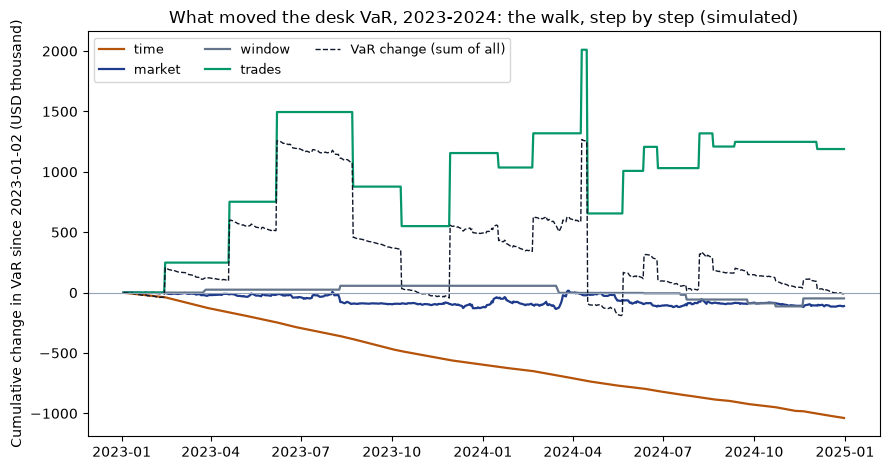

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    r'C:\Users\franklinpeng\Desktop\RDA Risk test\DataSource\rates_desk_feed.csv',
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100


def ladder_states(Q, K, KA):
    """TODO: The four ladders of every morning's walk, each (days x 11) in USD per bp. Q = positions in USD units
    (days x bonds); K, KA from history(). For morning t:
      L0 = yesterday's report:     Q[t-1] with K[t-1]
      L1 = + one day older:        Q[t-1] with KA[t]   (same positions, aged a day, still on yesterday's curve)
      L2 = + today's curve:        Q[t-1] with K[t]
      L3 = + today's trades:       Q[t]   with K[t]    (= today's report)
    Row 0 has no yesterday: use row 0 as its own t-1. Ladder of a book = sum over bonds of Q x K (np.einsum)."""
    q_prev = np.vstack([Q[:1], Q[:-1]])
    k_prev = np.vstack([K[:1], K[:-1]])

    L0 = np.einsum('nb,nbk->nk', q_prev, k_prev)
    L1 = np.einsum('nb,nbk->nk', q_prev, KA)
    L2 = np.einsum('nb,nbk->nk', q_prev, K)
    L3 = np.einsum('nb,nbk->nk', Q, K)

    return L0, L1, L2, L3


def var(ladder, window):
    """TODO: 1-day 99% HS VaR (USD) of one ladder over a window of daily moves (rows, bp): minus the VAR_K-th worst
    of -window @ ladder."""
    pnl = -window @ ladder
    return -float(np.partition(pnl, VAR_K - 1)[VAR_K - 1])



def var_states(L, moves, t):
    """TODO: The five VaRs of morning t. L = (L0, L1, L2, L3) from ladder_states; moves[s] = the curve move INTO day s
    (bp). Yesterday's window = moves[t - VAR_DAYS : t]; today's window = moves[t - VAR_DAYS + 1 : t + 1].
      V0 = L0 on yesterday's window     V1 = L1 on yesterday's     V2 = L2 on yesterday's
      V3 = L2 on TODAY's window         V4 = L3 on today's window  (= today's report)"""
    yesterday = moves[t - VAR_DAYS:t]
    today = moves[t - VAR_DAYS + 1:t + 1]

    L0, L1, L2, L3 = L

    return (
        var(L0[t], yesterday),
        var(L1[t], yesterday),
        var(L2[t], yesterday),
        var(L2[t], today),
        var(L3[t], today),
    )


# ---------------------------------------------------------------------------
H = history(Z)
Q = positions_history() * UNIT
moves = np.vstack([np.zeros((1, 11)), np.diff(Z, axis=0) * 100])
checks = [('ladder_states', lambda: ladder_states(Q[:3], H['K'][:3], H['KA'][:3])),
          ('var', lambda: var(np.ones(11), moves[1:11])),
          ('var_states', lambda: var_states((np.ones((600, 11)),) * 4, moves, 520))]
todo = next((name for name, f in checks if f() is None), None)
if todo:
    print(f"Fill in the TODOs above, then run again. Next: {todo}()")
else:
    L = ladder_states(Q, H['K'], H['KA'])
    L0, L1, L2, L3 = L
    V = np.array([var_states(L, moves, t) for t in REP])
    dv = pd.DataFrame({'time': (L1 - L0).sum(1), 'market': (L2 - L1).sum(1), 'trades': (L3 - L2).sum(1)},
                      index=DATES)
    dv['start'], dv['end'] = L0.sum(1), L3.sum(1)
    dv = dv.iloc[REP]
    vr = pd.DataFrame({'start': V[:, 0], 'time': V[:, 1] - V[:, 0], 'market': V[:, 2] - V[:, 1],
                       'window': V[:, 3] - V[:, 2], 'trades': V[:, 4] - V[:, 3], 'end': V[:, 4]}, index=DATES[REP])
    chain = np.max(np.abs(L3[REP[:-1]] - L0[REP[1:]]))
    print(f"Today's report is tomorrow's starting point (ladders, every morning): within USD 1e-6: {bool(chain < 1e-6)}")
    print(f"Net DV01 at the close of {DATES[-1].date()}: USD {L3[-1].sum():+,.0f};  VaR USD {V[-1, 4]:,.0f}")

    def show(day):
        r, s = dv.loc[day], vr.loc[day]
        print(f"\nThe walk for the morning of {pd.Timestamp(day).date()}:")
        print(f"  {'step':<26}{'net DV01':>12}{'VaR 99%':>12}")
        first, last = "yesterday's report", "= today's report"
        print(f"  {first:<26}{r.start:>+12,.0f}{s.start:>12,.0f}")
        for k, lbl in (('time', '+ one day older'), ('market', "+ today's curve"), ('window', "+ today's move in the window"),
                       ('trades', "+ today's trades")):
            a = f"{r[k]:>+12,.0f}" if k in r else f"{'':>12}"
            print(f"  {lbl:<26}{a}{s[k]:>+12,.0f}")
        print(f"  {last:<26}{r.end:>+12,.0f}{s.end:>12,.0f}")

    show(DATES[-1])
    y24 = vr.index.year == 2024
    show(vr[y24]['window'].abs().idxmax())

    for yr in (2023, 2024):
        a, b = dv[dv.index.year == yr], vr[vr.index.year == yr]
        print(f"\n{yr}: {len(a)} mornings")
        print(f"  {'':<8}{'start':>11}{'time':>11}{'market':>11}{'window':>11}{'trades':>11}{'end':>11}")
        print(f"  {'DV01':<8}{a.start.iloc[0]:>+11,.0f}{a.time.sum():>+11,.0f}{a.market.sum():>+11,.0f}{'':>11}"
              f"{a.trades.sum():>+11,.0f}{a.end.iloc[-1]:>+11,.0f}")
        print(f"  {'VaR':<8}{b.start.iloc[0]:>11,.0f}{b.time.sum():>+11,.0f}{b.market.sum():>+11,.0f}"
              f"{b.window.sum():>+11,.0f}{b.trades.sum():>+11,.0f}{b.end.iloc[-1]:>11,.0f}")
        for name, t, cols in (('DV01', a, ['time', 'market', 'trades']), ('VaR', b, ['time', 'market', 'window', 'trades'])):
            big = t[cols].abs().idxmax(axis=1).value_counts().reindex(cols, fill_value=0)
            print(f"  {name} largest step on: " + ', '.join(f"{c} {big[c]}" for c in cols) + " mornings")
            print(f"  {name} time step below zero on {(t.time < 0).sum()} of {len(t)} mornings; market step moved "
                  f"{t.market.abs().sum():,.0f} in all and netted {t.market.sum():+,.0f}")

    m24 = np.where(DATES[REP].year == 2024)[0]
    steps = {'time': (L1 - L0)[REP][m24].sum(0), 'market': (L2 - L1)[REP][m24].sum(0), 'trades': (L3 - L2)[REP][m24].sum(0)}
    print("\n2024 ladder changes by step (USD per bp):")
    print(f"  {'vertex':<7}" + ''.join(f"{k:>11}" for k in steps) + f"{'start':>11}{'end':>11}")
    for k, lbl in enumerate(LAB):
        print(f"  {lbl:<7}" + ''.join(f"{steps[s][k]:>+11,.0f}" for s in steps)
              + f"{L0[REP][m24[0]][k]:>+11,.0f}{L3[REP][m24[-1]][k]:>+11,.0f}")

    fig, ax = plt.subplots(figsize=(9, 4.8))
    c = vr[['time', 'market', 'window', 'trades']].cumsum() / 1e3
    for k, col in (('time', '#b45309'), ('market', '#1e3a8a'), ('window', '#64748b'), ('trades', '#059669')):
        ax.plot(c.index, c[k], color=col, lw=1.6, label=f'{k}')
    ax.plot(vr.index, (vr.end - vr.start.iloc[0]) / 1e3, color='#0f172a', lw=1, ls='--', label='VaR change (sum of all)')
    ax.axhline(0, color='#94a3b8', lw=0.8)
    ax.set_ylabel('Cumulative change in VaR since 2023-01-02 (USD thousand)')
    ax.set_title('What moved the desk VaR, 2023-2024: the walk, step by step (simulated)')
    ax.legend(ncol=3, fontsize=9)
    plt.tight_layout()
    plt.show()
